# 05 — Presentation figures (artifact simulation)

Notebook reproducing the B1 / B2 and C1 / C2 figures using the projects code.
Edit the style cell to change typography, colours and sizes; each plot is written
inline (no helper functions) so it is easily customisable.

In [1]:
"""Presentation style copied from the reference notebook."""

import pathlib

import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.font_manager import FontProperties, findfont

# ── colour ────────────────────────────────────────────────────────────────────
C_SERIES_3 = '#7C2D12'   # Umbra     — darkest, the subject
C_SERIES_4 = '#B45309'   # Penumbra
C_SERIES_1 = '#E8890C'   # Both
C_SERIES_2 = '#FCD34D'   # Quiet Sun — lightest, the baseline
C_ACCENT   = '#D97706'   # single-series highlight
C_INK      = '#241A12'   # text and axes
C_GRID     = '#E7DCCC'   # grid
C_FIG_BG   = '#FDF8F1'   # figure background

PALETTE = [C_SERIES_1, C_SERIES_2, C_SERIES_3, C_SERIES_4]

# Region → colour, so "the umbra is always the darkest" holds in every figure.
REGION_COLOR = {
    'Umbra':     C_SERIES_1,
    'Penumbra':  C_SERIES_2,
    'Both':      C_SERIES_3,
    'Quiet Sun': C_SERIES_4,
}

# (label, metrics-key suffix), in drawing order.
REGIONS = [('Umbra', 'umb'), ('Penumbra', 'pen'),  ('Quiet Sun', 'quiet')]

# The same ramp as a sequential colormap — for quantities that are a magnitude
CMAP_AMBER = LinearSegmentedColormap.from_list(
    'amber', ['#451A03', C_SERIES_1, C_SERIES_2, C_SERIES_3, C_SERIES_4])

# ── typography ────────────────────────────────────────────────────────────────
FONT_SANS = ['Jost', 'IBM Plex Sans', 'DejaVu Sans']
FONT_MONO = ['JetBrains Mono', 'JetBrainsMono Nerd Font', 'DejaVu Sans Mono']

# ── sizes ─────────────────────────────────────────────────────────────────────
FS_TITLE  = 26
FS_LABEL  = 20
FS_TICK   = 17
FS_LEGEND = 18
FS_ANNOT  = 14

LW_SERIES = 2.4
LW_GRID   = 1.0
LW_SPINE  = 1.6

FIGSIZE_WIDE  = (16, 8)
FIGSIZE_STACK = (16, 10)
DPI_SHOW = 110
DPI_SAVE = 200

# ── output ───────────────────────────────────────────────────────────────────
SAVE = False
PLOTS_DIR = None

plt.rcParams.update({
    'font.family':      'sans-serif',
    'font.sans-serif':  FONT_SANS,
    'font.monospace':   FONT_MONO,
    'font.size':        FS_LABEL,

    'figure.figsize':     FIGSIZE_WIDE,
    'figure.dpi':         DPI_SHOW,
    'figure.facecolor':   C_FIG_BG,
    'figure.titlesize':   FS_TITLE,
    'figure.titleweight': 'semibold',

    'savefig.facecolor': C_FIG_BG,
    'savefig.dpi':       DPI_SAVE,
    'savefig.bbox':      'tight',

    'axes.facecolor':     C_FIG_BG,
    'axes.edgecolor':     C_INK,
    'axes.linewidth':     LW_SPINE,
    'axes.labelcolor':    C_INK,
    'axes.labelsize':     FS_LABEL,
    'axes.labelweight':   'medium',
    'axes.titlesize':     FS_TITLE,
    'axes.titleweight':   'semibold',
    'axes.titlecolor':    C_INK,
    'axes.titlepad':      14,
    'axes.spines.top':    False,
    'axes.spines.right':  False,
    'axes.prop_cycle':    cycler(color=PALETTE),
    'axes.grid':          True,
    'axes.axisbelow':     True,

    'grid.color':     C_GRID,
    'grid.linewidth': LW_GRID,
    'grid.alpha':     1.0,

    'lines.linewidth':       LW_SERIES,
    'lines.solid_capstyle':  'round',

    'text.color':        C_INK,
    'xtick.color':       C_INK,
    'ytick.color':       C_INK,
    'xtick.labelsize':   FS_TICK,
    'ytick.labelsize':   FS_TICK,
    'xtick.major.width': LW_SPINE,
    'ytick.major.width': LW_SPINE,
    'xtick.major.size':  6,
    'ytick.major.size':  6,

    'legend.fontsize':   FS_LEGEND,
    'legend.frameon':    True,
    'legend.facecolor':  C_FIG_BG,
    'legend.edgecolor':  C_GRID,
    'legend.framealpha': 1.0,
    'legend.borderpad':  0.6,
})

def mono_ticks(*axes):
    for ax in axes:
        for label in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
            label.set_fontfamily('monospace')
            label.set_fontsize(FS_TICK)

def save_fig(fig, name):
    if not SAVE or PLOTS_DIR is None:
        return
    out_dir = pathlib.Path(PLOTS_DIR)
    out_dir.mkdir(parents=True, exist_ok=True)
    out = out_dir / f'{name}.png'
    fig.savefig(out, dpi=DPI_SAVE, bbox_inches='tight', facecolor=C_FIG_BG)
    print(f'saved → {out}')

for role, stack in (('sans', FONT_SANS), ('mono', FONT_MONO)):
    resolved = pathlib.Path(findfont(FontProperties(family=stack))).name
    print(f'{role:5s} {stack[0]:20s} → {resolved}')

sans  Jost                 → IBMPlexSans-Regular.ttf
mono  JetBrains Mono       → JetBrainsMonoNerdFont-Regular.ttf


In [2]:
# Data computation for B and C figures (inline, editable)",
import pathlib, sys
import numpy as np
import matplotlib.pyplot as plt

project_root = pathlib.Path.cwd()
# Walk upwards until we find the directory that contains the package folder
while project_root != project_root.parent and not (project_root / 'hmi_artifact_sim').exists():
    project_root = project_root.parent
if (project_root / 'hmi_artifact_sim').exists():
    # add the parent that contains the package to sys.path
    sys.path.insert(0, str(project_root.resolve()))
else:
    # fallback: add cwd
    sys.path.insert(0, str(pathlib.Path.cwd().resolve()))
from hmi_artifact_sim import config as cfg
from hmi_artifact_sim.pipeline import LookupTable
from hmi_artifact_sim.artifact import measure_artifact
lut = LookupTable()
lut_ext = LookupTable(v_min=cfg.LUT_V_MIN_EXT, v_max=cfg.LUT_V_MAX_EXT, n=cfg.LUT_N_EXT)

# --- B: artifact vs Wilson depression (B = cfg.B_GAUSS) ---
z = np.linspace(0.0, 800.0, 161)
obs_levels = [0.0, 1000.0, 2000.0, 3000.0]
curves = {}
for ov in obs_levels:
    curves[ov] = np.array([measure_artifact(zi, cfg.B_GAUSS, 0.0, ov, lookup=lut)[0] for zi in z])

# Decomposition at OBS_VR = 3000 (Wilson-only, Zeeman-only)
z_only = np.array([measure_artifact(zi, 0.0, 0.0, 3000.0, lookup=lut)[0] for zi in z])
b_only = measure_artifact(0.0, cfg.B_GAUSS, 0.0, 3000.0, lookup=lut)[0]

# --- C: 24 h temporal signature ---
n = 2048
t = np.linspace(0.0, 48.0, n, endpoint=False)
obs = cfg.A_ORB * np.sin(2 * np.pi * t / cfg.P_ORB_HOURS)
art, vdop, blos = measure_artifact(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, obs, lookup=lut)
art_e, _, blos_e = measure_artifact(cfg.Z_W_REF, cfg.B_GAUSS, 0.0, obs, lookup=lut_ext)

print('computed curves: B and C series ready')

computed curves: B and C series ready


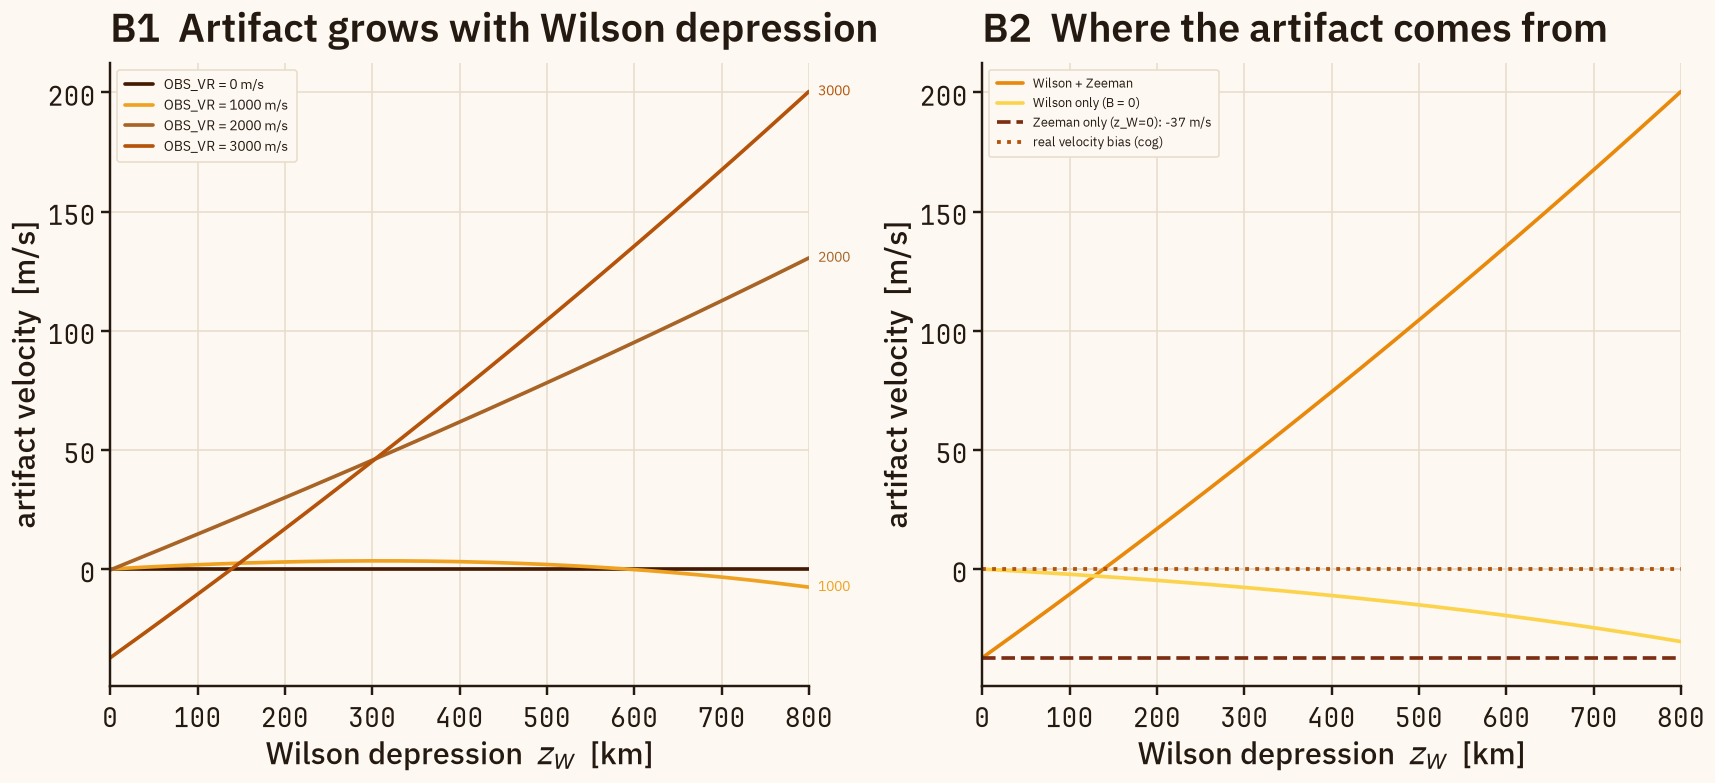

In [3]:
# B1 + B2: artifact vs Wilson depression and decomposition
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
ax = axes[0]
ax.axhline(0, color=C_GRID, lw=1)
for k, ov in enumerate(obs_levels):
    ax.plot(z, curves[ov], color=CMAP_AMBER(k / (len(obs_levels) - 1)),
            label=f'OBS_VR = {ov:.0f} m/s')
    if ov > 0:
        ax.annotate(f'{ov:.0f}', xy=(z[-1], curves[ov][-1]),
                    xytext=(6, 0), textcoords='offset points',
                    color=CMAP_AMBER(k / (len(obs_levels) - 1)), fontsize=9, va='center')
ax.set_xlabel('Wilson depression  $z_W$  [km]')
ax.set_ylabel('artifact velocity  [m/s]')
ax.set_title('B1  Artifact grows with Wilson depression', loc='left')
ax.legend(loc='upper left', fontsize=9)

ax = axes[1]
ax.axhline(0, color=C_GRID, lw=1)
ax.plot(z, curves[3000.0], color=PALETTE[0], label='Wilson + Zeeman')
ax.plot(z, z_only, color=PALETTE[1], label='Wilson only (B = 0)')
ax.axhline(float(b_only), color=PALETTE[2], ls='--',
           label=f'Zeeman only (z_W=0): {float(b_only):.0f} m/s')
ax.axhline(0, color=PALETTE[3], lw=2.5, ls=':', label='real velocity bias (cog)')
ax.set_xlabel('Wilson depression  $z_W$  [km]')
ax.set_ylabel('artifact velocity  [m/s]')
ax.set_title('B2  Where the artifact comes from', loc='left')
ax.legend(loc='upper left', fontsize=8.5)

for a in axes:
    a.set_xlim(z[0], z[-1])

mono_ticks(*axes)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_fig(fig, 'expB_wilson_sweep')
plt.show()

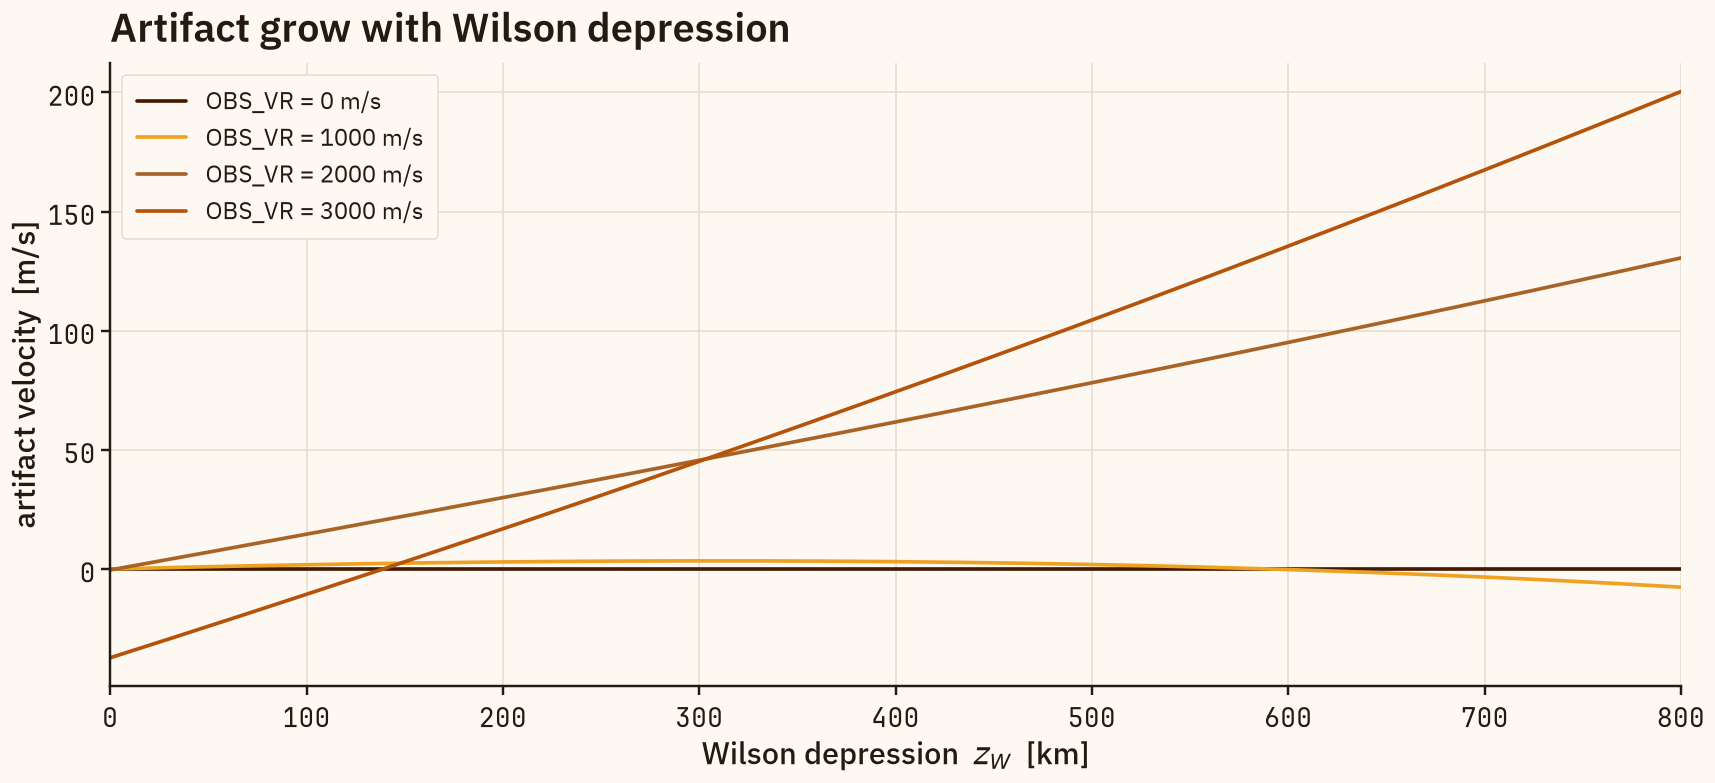

In [11]:
# B1 + B2: artifact vs Wilson depression and decomposition
fig, axes = plt.subplots(1, 1, figsize=(16, 8))
ax = axes
ax.axhline(0, color=C_GRID, lw=1)
for k, ov in enumerate(obs_levels):
    ax.plot(z, curves[ov], color=CMAP_AMBER(k / (len(obs_levels) - 1)),
            label=f'OBS_VR = {ov:.0f} m/s')

ax.set_xlabel('Wilson depression  $z_W$  [km]')
ax.set_ylabel('artifact velocity  [m/s]')
ax.set_title('Artifact grow with Wilson depression', loc='left')
ax.legend(loc='upper left', fontsize=16)

ax.set_xlim(z[0], z[-1])

mono_ticks(axes)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_fig(fig, 'expB_wilson_sweep')
plt.show()

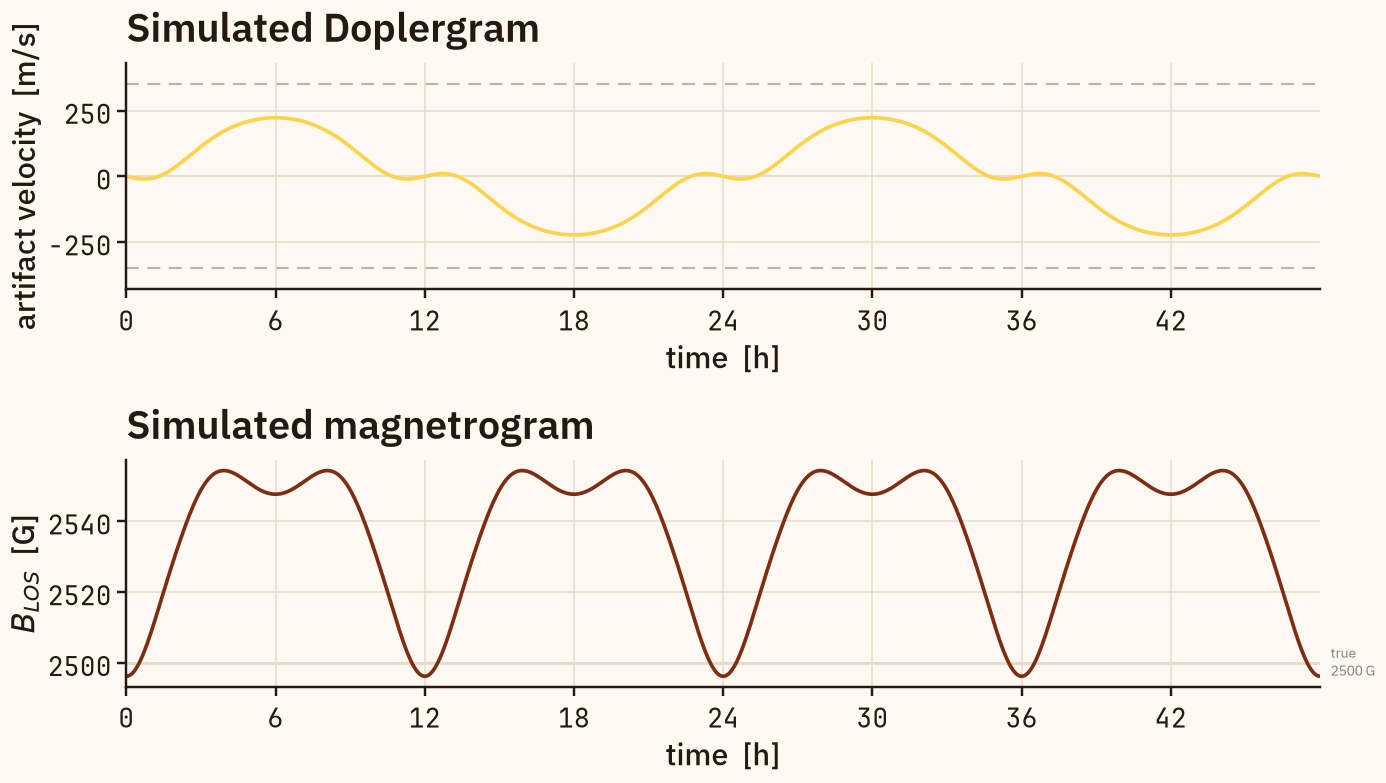

In [ ]:
# C1 + C2: 24 h temporal signature and magnetogram contamination
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=False)
ax = axes[0]
ax.axhline(cfg.V_OBSERVED_RESIDUAL, color='#b9b5a7', lw=1.4, ls=(0, (6, 4)), zorder=0)
ax.axhline(-cfg.V_OBSERVED_RESIDUAL, color='#b9b5a7', lw=1.4, ls=(0, (6, 4)), zorder=0)
#ax.text(48.4, cfg.V_OBSERVED_RESIDUAL, ' observed\n ±350 m/s',
#       color='"' + C_INK + '"' if False else 'gray', fontsize=9, va='center')
ax.set_ylim(-430, 430)
ax.axhline(0, color=C_GRID, lw=1)
#ax.plot(t, art, color=PALETTE[0], label='spec LUT (±7000 m/s)')
ax.plot(t, art_e, color=PALETTE[1], label='extended LUT (±9500 m/s)')
ax.set_xlabel('time  [h]')
ax.set_ylabel('artifact velocity  [m/s]')
ax.set_xticks(np.arange(0, 49, 6))
ax.set_title('Simulated Doplergram', loc='left')
#ax.legend(loc='upper left', fontsize=9, ncol=2)

ax = axes[1]
ax.axhline(cfg.B_GAUSS, color=C_GRID, lw=2)
#ax.text(48.3, cfg.B_GAUSS, ' true\n 2500 G', color='gray', fontsize=9, va='center')
ax.plot(t, blos, color=PALETTE[2])
ax.set_xlabel('time  [h]')
ax.set_ylabel('$B_{LOS}$  [G]')
ax.set_xticks(np.arange(0, 49, 6))
ax.set_title('Simulated magnetrogram', loc='left')

for a in axes:
    a.set_xlim(t[0], t[-1])

mono_ticks(*axes)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save_fig(fig, 'expC_24h_signature')
plt.show()

## D — Power spectrum of the 24 h signature

Both the artifact and the magnetogram contamination are periodic responses to a
single sinusoidal drive (`OBS_VR`, 24 h), so their spectra are line spectra:
harmonics of the orbital frequency, the Dopplergram on the odd ones and
$B_{LOS}$ on the even ones. The cell below reuses `t`, `art_e` and `blos` from
the C cell, follows the DS01 layout (two y axes, one grid) and prints the 5
tallest peaks of each signal relative to its own first peak.

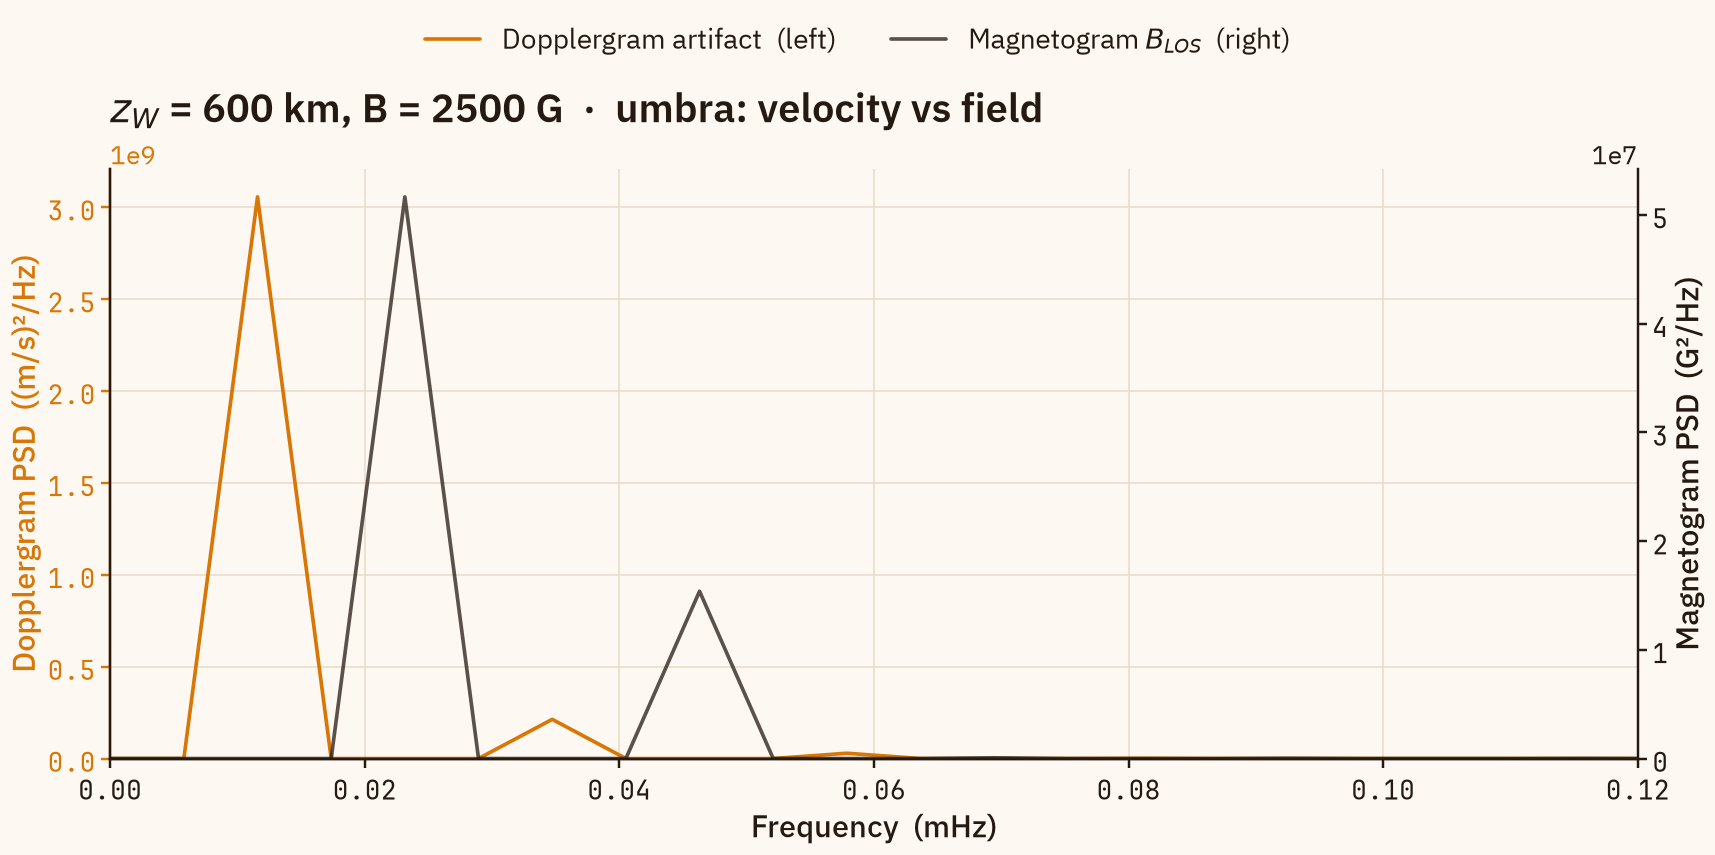


Dopplergram artifact
  rank  freq (mHz)  period (min)  period (h)        power  relative
     1     0.01157        1440.0       24.00   3.0559e+09   1.00000
     2     0.03472         480.0        8.00   2.1321e+08   0.06977
     3     0.05787         288.0        4.80   2.8882e+07   0.00945
     4     0.08102         205.7        3.43   1.1186e+06   0.00037
     5     0.10417         160.0        2.67   2.4709e+04   0.00001

Magnetogram $B_{LOS}$
  rank  freq (mHz)  period (min)  period (h)        power  relative
     1     0.02315         720.0       12.00   5.1667e+07   1.00000
     2     0.04630         360.0        6.00   1.5389e+07   0.29785
     3     0.06944         240.0        4.00   6.6928e+04   0.00130
     4     0.09259         180.0        3.00   2.5760e+04   0.00050
     5     0.11574         144.0        2.40   1.2474e+04   0.00024


In [6]:
# D01 — 24 h signature: dopplergram vs magnetogram, each on its own axis
XLIM    = (0, 0.12)        # mHz; harmonics of the 24 h orbit live below this
N_PEAKS = 5                # peaks listed per signal

cadence_s = (t[1] - t[0]) * 3600.0        # sampling step of the C series, seconds

def psd_spectrum(y, cadence_s):
    """One-sided periodogram of y: frequency in mHz, power in units^2/Hz."""
    y = np.asarray(y, float) - np.mean(y)
    n = y.size
    fs = 1.0 / cadence_s
    power = 2.0 * np.abs(np.fft.rfft(y)) ** 2 / (fs * n)
    return np.fft.rfftfreq(n, d=cadence_s) * 1e3, power

def spectral_peaks(freq, power, n_peaks=N_PEAKS):
    """The n_peaks tallest local maxima, strongest first, relative to the first."""
    k = np.arange(1, power.size - 1)
    k = k[(power[k] > power[k - 1]) & (power[k] >= power[k + 1])]
    k = k[np.argsort(power[k])[::-1][:n_peaks]]
    return [{'rank': i, 'freq_mhz': freq[j], 'period_min': 1.0 / (freq[j] * 1e-3) / 60.0,
             'power': power[j], 'relative': power[j] / power[k[0]]}
            for i, j in enumerate(k, 1)]

freq_dop, power_dop = psd_spectrum(art_e, cadence_s)
freq_mag, power_mag = psd_spectrum(blos, cadence_s)

fig, ax_dop = plt.subplots(figsize=FIGSIZE_WIDE)
ax_mag = ax_dop.twinx()

# Two y-scales, so the height where the curves cross is set by the scaling, not by the
# data. Read each curve against its own axis and compare peak *positions*, not heights.
ax_dop.plot(freq_dop, power_dop, color=C_ACCENT, lw=LW_SERIES,
            label='Dopplergram artifact  (left)')
ax_mag.plot(freq_mag, power_mag, color=C_INK, lw=LW_SERIES, alpha=0.75,
            label='Magnetogram $B_{LOS}$  (right)')

ax_dop.set_ylabel('Dopplergram PSD  ((m/s)²/Hz)', color=C_ACCENT)
ax_mag.set_ylabel('Magnetogram PSD  (G²/Hz)', color=C_INK)
ax_dop.tick_params(axis='y', colors=C_ACCENT)
ax_mag.tick_params(axis='y', colors=C_INK)
ax_dop.spines['left'].set_color(C_ACCENT)
ax_mag.spines['right'].set_visible(True)
ax_mag.spines['right'].set_color(C_INK)
ax_mag.grid(False)                      # one grid only, from the left axis

ax_dop.set_xlim(*XLIM)
ax_dop.set_ylim(bottom=0)
ax_mag.set_ylim(bottom=0)
ax_dop.set_xlabel('Frequency  (mHz)')
ax_dop.set_title(f'$z_W$ = {cfg.Z_W_REF:.0f} km, B = {cfg.B_GAUSS:.0f} G'
                 '  ·  umbra: velocity vs field', loc='left')

mono_ticks(ax_dop, ax_mag)
fig.tight_layout(rect=(0, 0, 1, 0.93))

handles = ax_dop.get_lines() + ax_mag.get_lines()
fig.legend(handles, [h.get_label() for h in handles], ncol=2,
           loc='upper center', bbox_to_anchor=(0.5, 1.0), frameon=False)
save_fig(fig, 'expD_psd_compare_umbra')
plt.show()

for name, freq, power in (('Dopplergram artifact', freq_dop, power_dop),
                          ('Magnetogram $B_{LOS}$', freq_mag, power_mag)):
    peaks = spectral_peaks(freq, power)
    print(f'\n{name}')
    if not peaks:
        print('  no peaks above the threshold')
        continue
    print(f'  {"rank":>4} {"freq (mHz)":>11} {"period (min)":>13} {"period (h)":>11} '
          f'{"power":>12} {"relative":>9}')
    for r in peaks:
        print(f'  {r["rank"]:>4} {r["freq_mhz"]:>11.5f} {r["period_min"]:>13.1f} '
              f'{r["period_min"] / 60:>11.2f} {r["power"]:>12.4e} {r["relative"]:>9.5f}')

## E — The line profiles the pipeline sees

Same content as `figures/profiles.png`, re-drawn in the presentation style but
with **generic line colours** (only the background keeps the deck palette), and
with the six HMI filters drawn as Gaussian transmission profiles instead of bare
vertical lines, so the sampling geometry is visible against the line. The filters
are never in the legend.

E1 is the quiet Sun alone. E2 and E3 are the same figure — same title shape, same
structure, quiet Sun kept as a grey reference — differing only in that E3 adds the
Zeeman split *on top of* the Wilson deformation, so the umbral profile becomes its
two circular polarisations.

In [7]:
# Data for the E figures: line profiles and the 6 HMI filter transmissions
from hmi_artifact_sim.profiles import (quiet_profile, umbral_profile,
                                       wilson_parameters, zeeman_shift)
from hmi_artifact_sim.pipeline import filter_wavelengths

# ── knobs ────────────────────────────────────────────────────────────────────
LAM_HALF_WIDTH = 0.35      # Å plotted either side of lambda0
FILTER_FWHM    = 0.076     # Å, HMI tunable-filter transmission FWHM
YLIM           = (0.0, 1.0)
Z_W_PLOT       = cfg.Z_W_REF     # km, the "arbitrary" Wilson depression shown
B_PLOT         = cfg.B_GAUSS     # G, the field used for the Zeeman split

# Generic line colours — deliberately *not* the presentation palette, so the
# physics reads on its own; only the background stays in the deck style.
# Red and blue are reserved for the transformations (LCP / RCP), so the six
# filters take the remaining generic hues.
C_QUIET   = 'black'
C_REF     = '0.35'          # the quiet profile when it is just a reference
C_WILSON  = 'tab:blue'
C_LCP     = 'tab:red'
C_RCP     = 'tab:blue'
C_FILTERS = ['tab:green', 'tab:orange', 'tab:purple',
             'tab:brown', 'tab:olive', 'tab:pink']

# ── profiles ─────────────────────────────────────────────────────────────────
lam = cfg.LAMBDA0 + np.linspace(-LAM_HALF_WIDTH, LAM_HALF_WIDTH, 1200)
dlam = lam - cfg.LAMBDA0                       # x axis: lambda - lambda0

# The Zeeman split is applied *on top of* the Wilson deformation, so E3 is E2
# with the umbral profile split into its two circular polarisations.
I_quiet  = quiet_profile(lam)
I_wilson = umbral_profile(lam, z_W=Z_W_PLOT, B_gauss=0.0)
I_lcp    = umbral_profile(lam, z_W=Z_W_PLOT, B_gauss=B_PLOT, polarization='LCP')
I_rcp    = umbral_profile(lam, z_W=Z_W_PLOT, B_gauss=B_PLOT, polarization='RCP')

# ── the six filters, as Gaussian transmission profiles ───────────────────────
# I0..I5 in order of decreasing wavelength, the pipeline's own convention.
lam_filters = filter_wavelengths() - cfg.LAMBDA0
sigma_f = FILTER_FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))
filters = [np.exp(-0.5 * ((dlam - c) / sigma_f) ** 2) for c in lam_filters]

def draw_filters(ax, alpha=1.0):
    """The 6 filter transmissions, full scale: 0 = opaque, 1 = full throughput.

    Never labelled: they are context, and they would crowd every legend.
    """
    for i, T in enumerate(filters):
        ax.plot(dlam, T, color=C_FILTERS[i], lw=1.8, alpha=alpha, zorder=1,
                label='_nolegend_')

def top_legend(fig, ax, **kw):
    """Legend above the axes — the frame is left clear for the profiles."""
    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, ncol=kw.pop('ncol', len(labels)),
               loc='upper center', bbox_to_anchor=(0.5, 1.0),
               frameon=False, fontsize=FS_LEGEND, **kw)

dlB = zeeman_shift(B_PLOT)
Ic_w, Id_w, sg_w = wilson_parameters(Z_W_PLOT)
print(f'Zeeman shift at {B_PLOT:.0f} G : {dlB * 1e3:.1f} mA '
      f'= {dlB / cfg.SIGMA_QUIET:.2f} sigma')
print(f'Wilson at {Z_W_PLOT:.0f} km   : Ic {cfg.IC_QUIET:.3f} -> {Ic_w:.3f}, '
      f'Id {cfg.ID_QUIET:.3f} -> {Id_w:.3f}, sigma {cfg.SIGMA_QUIET:.4f} -> {sg_w:.4f} A')
print(f'filter FWHM {FILTER_FWHM * 1e3:.0f} mA, positions [mA]: '
      f'{np.round(lam_filters * 1e3, 1)}')

Zeeman shift at 2500 G : 111.2 mA = 1.85 sigma
Wilson at 600 km   : Ic 1.000 -> 0.750, Id 0.550 -> 0.468, sigma 0.0600 -> 0.0540 A
filter FWHM 76 mA, positions [mA]: [ 172.   103.2   34.4  -34.4 -103.2 -172. ]


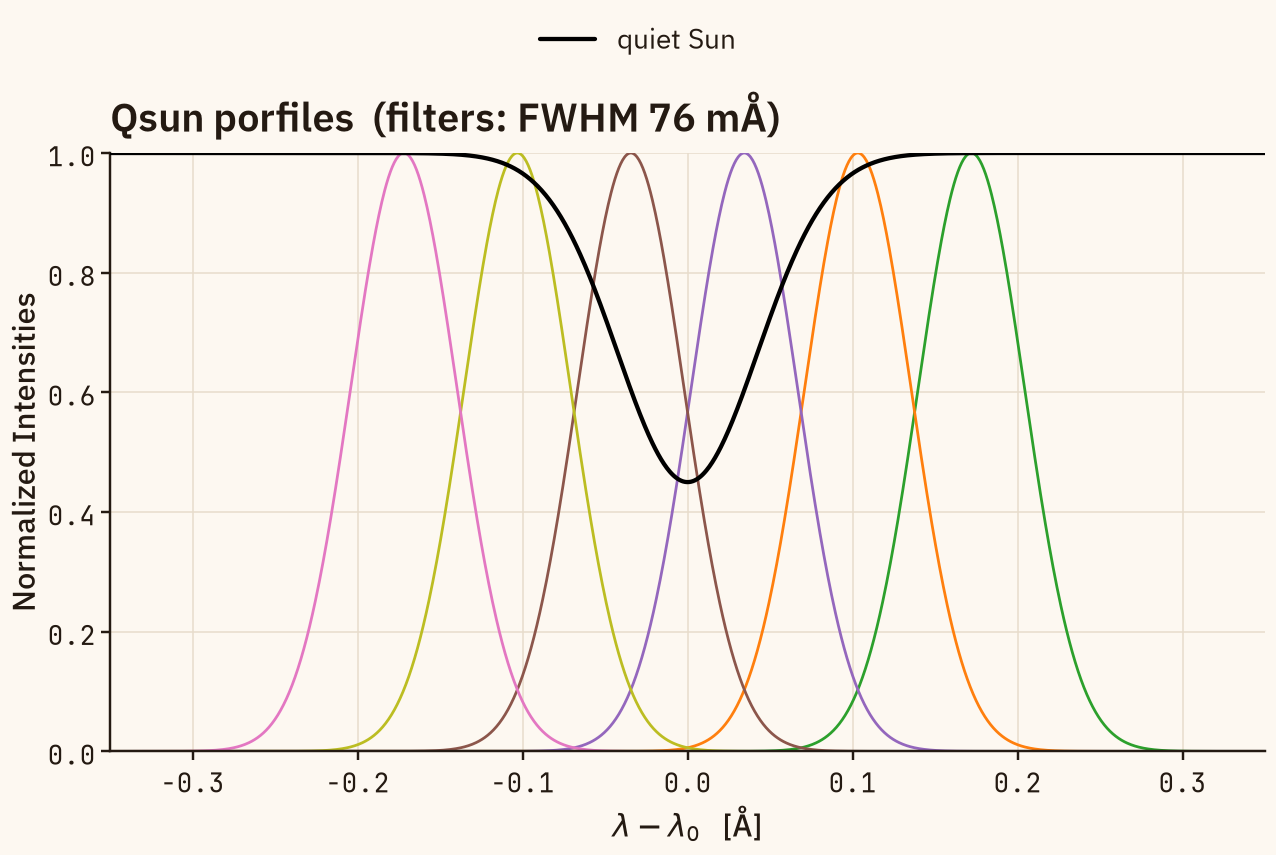

In [8]:
# E1 — the quiet-Sun profile and the six HMI filters
fig, ax = plt.subplots(figsize=(12, 8))

draw_filters(ax, alpha=1.0)
ax.plot(dlam, I_quiet, color=C_QUIET, lw=LW_SERIES + 0.4, label='quiet Sun', zorder=3)

ax.set_xlim(dlam[0], dlam[-1])
ax.set_ylim(*YLIM)
ax.set_xlabel('$\\lambda - \\lambda_0$   [Å]')
ax.set_ylabel('Normalized Intensities')
ax.set_title(f'Qsun porfiles  '
             f'(filters: FWHM {FILTER_FWHM * 1e3:.0f} mÅ)', loc='left')

mono_ticks(ax)
fig.tight_layout(rect=(0, 0, 1, 0.93))
top_legend(fig, ax)
save_fig(fig, 'expE1_quiet_profile')
plt.show()

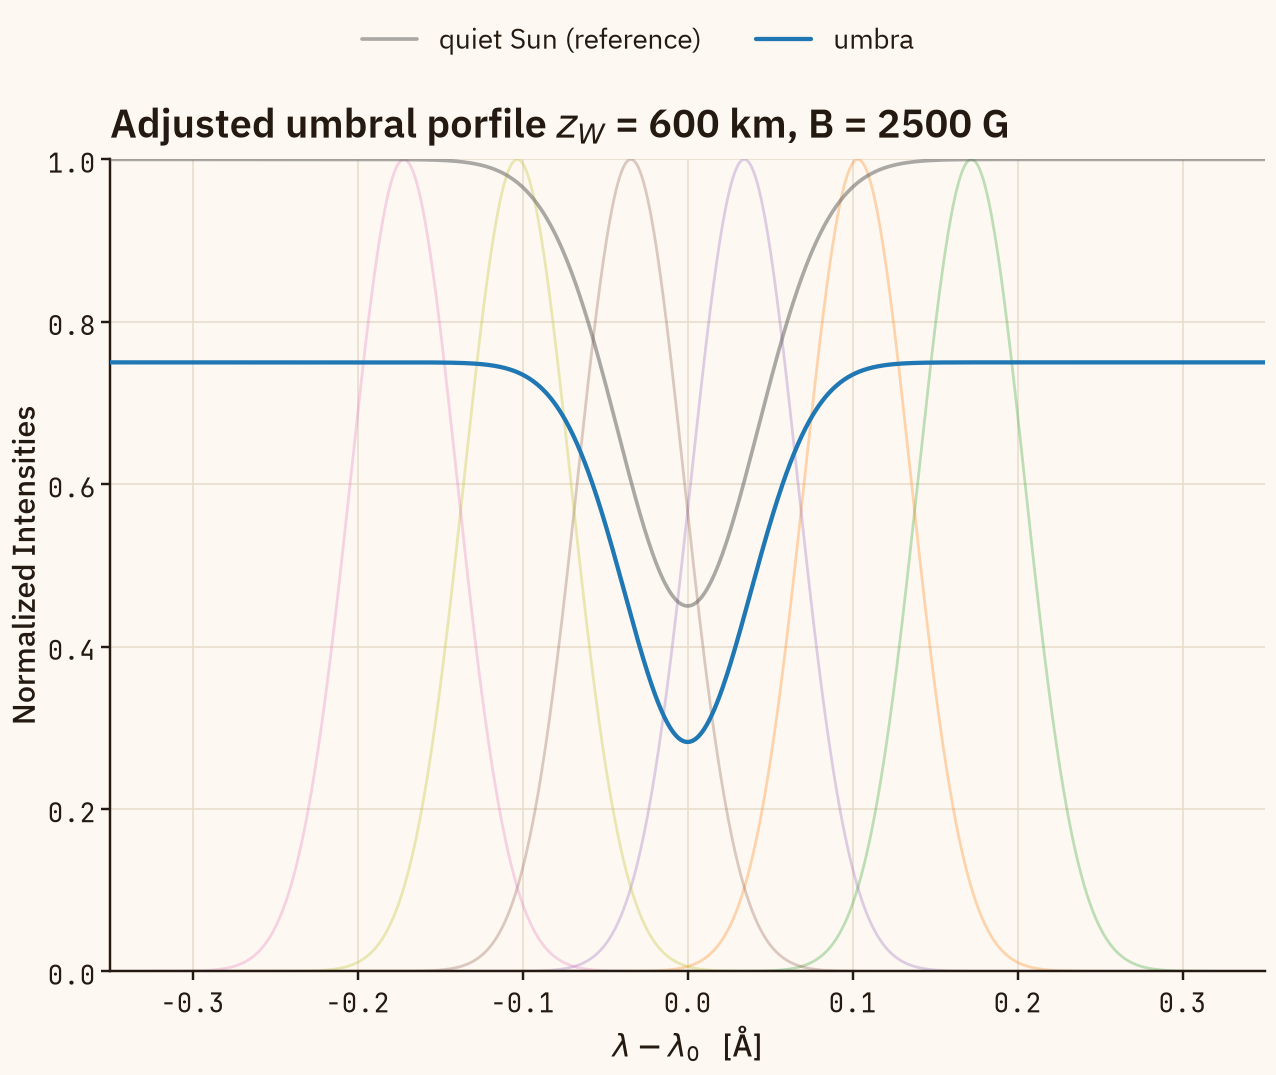

In [9]:
# E2 — the same profile deformed by the Wilson depression
fig, ax = plt.subplots(figsize=(12, 10))

draw_filters(ax, alpha=0.30)          # dimmed, and out of the legend
ax.plot(dlam, I_quiet, color=C_REF, lw=LW_SERIES, alpha=0.5, zorder=3,
        label='quiet Sun (reference)')
ax.plot(dlam, I_wilson, color=C_WILSON, lw=LW_SERIES + 0.4, zorder=4,
        label='umbra')

ax.set_xlim(dlam[0], dlam[-1])
ax.set_ylim(*YLIM)
ax.set_xlabel('$\\lambda - \\lambda_0$   [Å]')
ax.set_ylabel('Normalized Intensities')

ax.set_title(f'Adjusted umbral porfile $z_W$ = {Z_W_PLOT:.0f} km, B = {B_PLOT:.0f} G', loc='left')

mono_ticks(ax)
fig.tight_layout(rect=(0, 0, 1, 0.93))
top_legend(fig, ax)
save_fig(fig, 'expE2_wilson_profile')
plt.show()

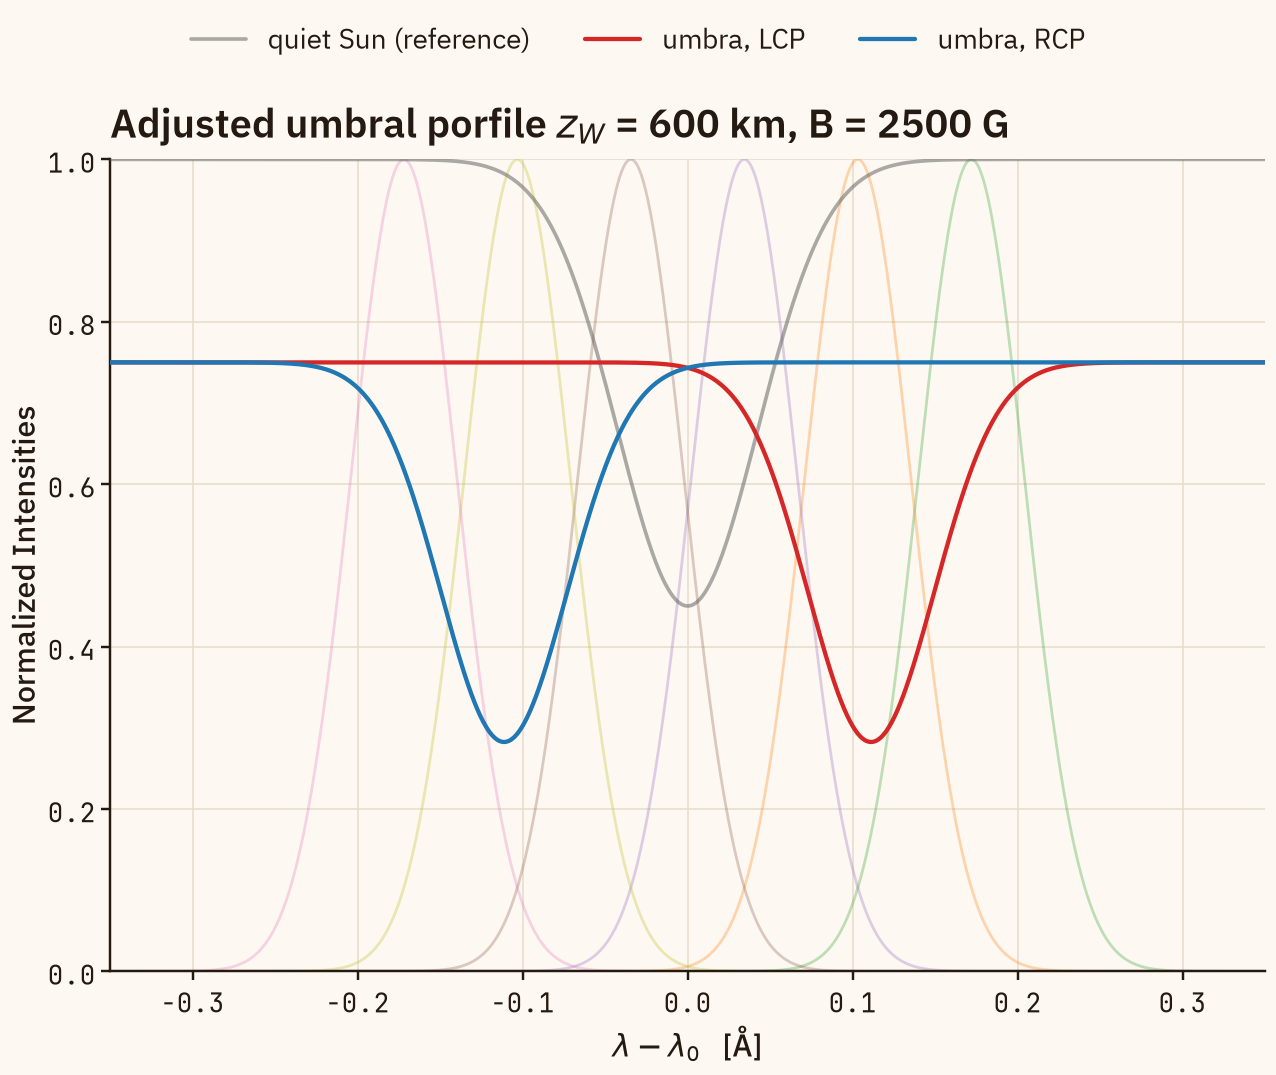

In [10]:
# E3 — E2 again, with the Zeeman split on top: same profile, now LCP + RCP
fig, ax = plt.subplots(figsize=(12, 10))

draw_filters(ax, alpha=0.30)          # dimmed, and out of the legend
ax.plot(dlam, I_quiet, color=C_REF, lw=LW_SERIES, alpha=0.5, zorder=3,
        label='quiet Sun (reference)')
ax.plot(dlam, I_lcp, color=C_LCP, lw=LW_SERIES + 0.4, zorder=4,
        label='umbra, LCP')
ax.plot(dlam, I_rcp, color=C_RCP, lw=LW_SERIES + 0.4, zorder=4,
        label='umbra, RCP')

ax.set_xlim(dlam[0], dlam[-1])
ax.set_ylim(*YLIM)
ax.set_xlabel('$\\lambda - \\lambda_0$   [Å]')
ax.set_ylabel('Normalized Intensities')

ax.set_title(f'Adjusted umbral porfile $z_W$ = {Z_W_PLOT:.0f} km, B = {B_PLOT:.0f} G',
             loc='left')

mono_ticks(ax)
fig.tight_layout(rect=(0, 0, 1, 0.93))
top_legend(fig, ax)
save_fig(fig, 'expE3_zeeman_profile')
plt.show()